**CMSE 830 Midterm Project, Fall 2026** | Shubham Koirala

In this notebook, i did all the IDA, defined question for EDA, and prepared Streamlit app.

# 02 Data quality and EDA

Analysis behind the Streamlit app (app.py). It covers the data, the quality checks, question asked, decisions made, and exploratory analysis. Everything here uses the processed files in data/processed/, prepared in previous notekook (notebooks/01_prepare_data.ipynb).

## 1. Purpose, audience and questions

**User:** a researcher who wants to understand the disease, in transcriptomic level (gene level), compare diseases, choose a disease model, and know how much to trust it for drug discovery.

**Central question:** How many independent datasets stand behind a disease signature, and do those datasets agree?

Three focused questions drive the EDA:

1. **Q1, representation:** How much evidence does the catalog have per disease? (Is dataset support balanced or concentrated?)
2. **Q2, strength:** Do genes with more supporting datasets look more significant or have larger effects?
3. **Q3, agreement:** Do more datasets bring more agreement between them (lower I²), or less?

In [55]:
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.color": "#eeeeee", "axes.axisbelow": True, "font.size": 10})
TIER_ORDER = ["low", "medium", "high"]
TIER_COLOR = {"low": "#440154", "medium": "#21918c", "high": "#7ad151"}   # three points on Viridis
TIER_LABEL = {"low": "Low (1 dataset)", "medium": "Medium (2 to 5)", "high": "High (6+)"}

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA = ROOT / "data" / "processed"

In [56]:
diseases = pd.read_csv(DATA / "disease_summary.csv")
genes    = pd.read_csv(DATA / "gene_sample.csv")      # 3% random sample of all gene rows, untested genes excluded
top      = pd.read_csv(DATA / "top_genes.csv")        # strongest 150 up + 150 down genes per disease
audit    = json.load(open(DATA / "audit.json"))        # exact counts from all 7.3 million rows
print(f"diseases {diseases.shape}, gene sample {genes.shape}, top genes {top.shape}")

diseases (350, 13), gene sample (200591, 8), top genes (105000, 8)


### 2. Data source and observation unit

- **Source:** OCTAD 2.0, my own in-preparation database of public RNA-seq disease versus normal comparisons. For each disease it combines every available dataset with a **random effects meta analysis**, giving one result per gene.
- **How obtained:** the per disease `*_meta.csv` files (350 of them) were stacked into one 1.8 GB file with a `disease` column. It has too many rows for GitHub or a free Streamlit deployment, so previous notebook streams through it once and writes the small tables used here.
- **Observation unit:** one row = **one gene in one disease** (about 20,800 genes per disease). The disease summary table has one row per disease.

| Variable | Role | Type |
|---|---|---|
| `disease` | grouping, user selection | categorical (350 levels) |
| `gene_symbol` | gene identity | text, high cardinality |
| `log2FoldChange_meta` | effect size (direction and size) | continuous, already log scaled |
| `padj_meta` | significance after multiple testing correction | continuous in [0, 1], very right skewed |
| `I2` | disagreement between datasets (0 to 100%) | continuous, only defined when 2+ datasets |
| `k_datasets` | datasets contributing to the gene's result | discrete count, 1 to 577, binned into tiers |

In [57]:
print(f"Rows in the full file: {audit['rows']:,} across {audit['diseases']} diseases")
audit_table = pd.DataFrame({
    "column": list(audit["na"].keys()),
    "missing rows": list(audit["na"].values()),
})
audit_table["share missing (%)"] = (audit_table["missing rows"] / audit["rows"] * 100).round(1)
audit_table

Rows in the full file: 7,273,417 across 350 diseases


,column,missing rows,share missing (%)
0,gene_symbol,0,0.0
1,log2FoldChange_meta,0,0.0
2,se_meta,4094093,56.3
3,pval_meta,586246,8.1
4,padj_meta,586246,8.1
5,I2,0,0.0
6,k_datasets,0,0.0


### 3. Data quality assessment

I checked every item below on the **full file** (counts are in `audit.json`) before choosing a repair. The question each time was whether the problem is a mistake to fix or a feature of the data to keep visible.

In [58]:
k1, rows = audit["k1_rows"], audit["rows"]
print("Missing adjusted p-values")
print(f"  total missing: {audit['na']['padj_meta']:,} ({audit['na']['padj_meta']/rows:.1%} of all rows)")
print(f"  among single dataset genes: {audit['padj_na_k1']:,} ({audit['padj_na_k1']/k1:.1%} of them)")
print(f"  among genes with 2+ datasets: {audit['padj_na_k2plus']:,}")
print()
print("I2 reported for single dataset genes")
print(f"  {audit['k1_i2_zero']:,} of {k1:,} single dataset rows report I2 = 0 (every one of them)")
print()
print("Adjusted p-value of exactly 0")
print(f"  {audit['padj_zero']:,} rows; also raw p = 0: {audit['padj_zero_and_p_zero']:,}; adjusted p below raw p: {audit['padj_below_p']:,}")
print()
print("Extreme fold changes (|log2FC| > 10)")
print(f"  {audit['abs_lfc_gt10']:,} rows, {audit['abs_lfc_gt10_k1']/audit['abs_lfc_gt10']:.0%} from single dataset genes")
print()
print("Duplicate gene symbols within a disease")
print(f"  {audit['dup_symbol_rows']:,} rows ({audit['dup_symbol_rows']/rows:.1%}) share a symbol with another row")

print()
untested = diseases["pct_genes_untested"]
print(f"Diseases with any untested genes: {(untested > 0).sum()} of {len(diseases)}; "
      f"diseases with more than half untested: {(untested > 50).sum()} ({diseases.loc[untested > 50, 'disease'].tolist()})")

Missing adjusted p-values
  total missing: 586,246 (8.1% of all rows)
  among single dataset genes: 586,246 (12.5% of them)
  among genes with 2+ datasets: 0

I2 reported for single dataset genes
  4,680,339 of 4,680,339 single dataset rows report I2 = 0 (every one of them)

Adjusted p-value of exactly 0
  12,105 rows; also raw p = 0: 12,105; adjusted p below raw p: 0

Extreme fold changes (|log2FC| > 10)
  10,788 rows, 94% from single dataset genes

Duplicate gene symbols within a disease
  265,858 rows (3.7%) share a symbol with another row

Diseases with any untested genes: 137 of 350; diseases with more than half untested: 1 (['Esophageal-Neoplasms'])


### Decisions and justification

| Issue | Finding | Decision | Why |
|---|---|---|---|
| **Missing adjusted p-values** | 586,246 rows (8.1%). Every one is a single dataset gene; none among genes with 2+ datasets. 137 of 350 diseases are affected (Esophageal Neoplasms: 91% untested). | **Not imputed.** Left blank, excluded from significance counts, shown as "% untested" per disease. | The gaps follow the dataset count, so they are not random. A filled in p-value would be invented evidence. |
| **I² = 0 for single dataset genes** | All 4.68 million single dataset rows report 0. | **Set to missing** for k = 1. | Disagreement cannot be measured from one study. A 0 would read as "perfect agreement". |
| **Adjusted p-value exactly 0** | 12,105 rows, all with raw p also 0 (numeric underflow). | **Kept.** Plot -log10(padj) capped at 50, cap drawn and labeled. | Dropping them would remove the strongest genes. Genes on the cap are not ranked against each other. |
| **Extreme fold changes**|log2FC| cap > 10 | 10,788 rows, 94% single dataset. | **Kept**, with k shown by color. | A huge change from one small study is a lead to verify, not noise to delete. |
| **Duplicate gene symbols** | 265,858 rows (3.7%): one symbol, several Ensembl IDs. | **Kept.** | No ID is clearly right; dropping one silently would hide the annotation issue. |
| **Skew** | Adjusted p-values pile up near 0; k runs 1 to 577. | **-log10 transform** (padj), **log axes** (k), **three tiers** for communication. | Raw scales hide almost all genes. |

**Unused column:** se_meta (standard error of meta analysis) is blank for 87.5% of single dataset genes and is never used here, so it was left alone.

**Encoding, scaling and modeling:** Not applied as Disease is only a selector, not a model input. Midterm is a descriptive app and the final project is where modeling belongs.

In [59]:
# Transformations used throughout
CAP = 50
genes["neglog10_padj"] = (-np.log10(genes["padj_meta"].clip(lower=1e-300))).clip(upper=CAP)
genes["abs_lfc"] = genes["log2FoldChange_meta"].abs()
genes["tier"] = pd.cut(genes["k_datasets"], [0, 1, 5, np.inf], labels=TIER_ORDER)
top["neglog10_padj"] = (-np.log10(top["padj_meta"].clip(lower=1e-300))).clip(upper=CAP)

# Verify the sample is representative of the full file
full_split = pd.Series({"low": audit["k1_rows"], "medium": audit["k2_5_rows"], "high": audit["k6_rows"]}) / audit["rows"] * 100
sample_split = genes["tier"].value_counts(normalize=True).reindex(TIER_ORDER) * 100
pd.DataFrame({"full file (%)": full_split.round(1), "3% sample (%)": sample_split.round(1)})

,full file (%),3% sample (%)
low,64.3,61.2
medium,26.5,28.8
high,9.1,10.0


### Visual checks of the quality issues

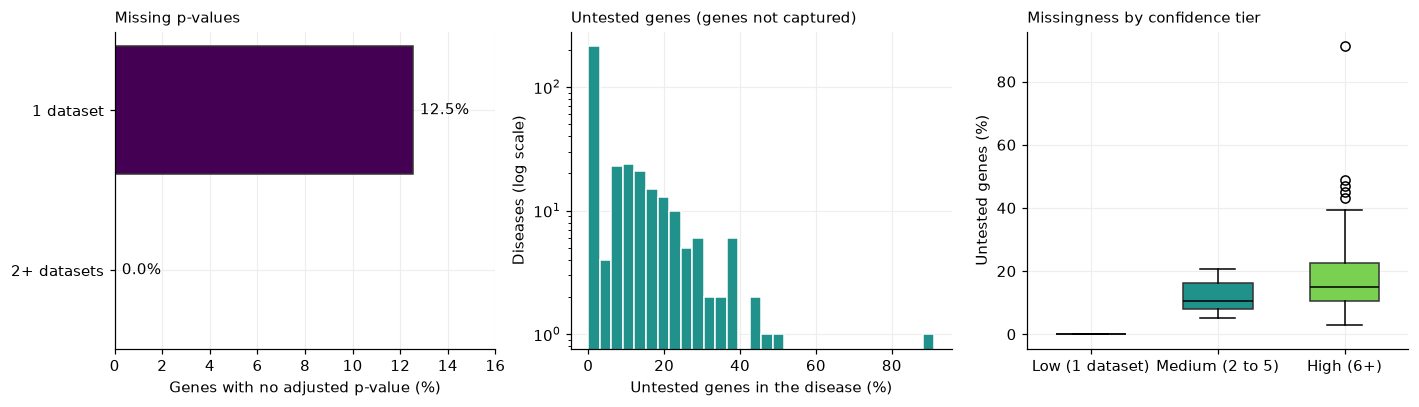

In [60]:
fig, ax = plt.subplots(1, 3, figsize=(13, 3.8))
share = [audit["padj_na_k1"] / audit["k1_rows"] * 100, audit["padj_na_k2plus"] / (audit["k2_5_rows"] + audit["k6_rows"]) * 100]
b = ax[0].barh(["1 dataset", "2+ datasets"], share, color=[TIER_COLOR["low"], TIER_COLOR["high"]], edgecolor="#333")
for bar, v in zip(b, share):
    ax[0].text(v + 0.3, bar.get_y() + bar.get_height() / 2, f"{v:.1f}%", va="center")
ax[0].set_xlim(0, 16); ax[0].set_xlabel("Genes with no adjusted p-value (%)"); ax[0].invert_yaxis()
ax[0].set_title("Missing p-values", fontsize=10, loc="left")

ax[1].hist(diseases["pct_genes_untested"], bins=30, color="#21918c", edgecolor="white")
ax[1].set_yscale("log"); ax[1].set_xlabel("Untested genes in the disease (%)"); ax[1].set_ylabel("Diseases (log scale)")
ax[1].set_title("Untested genes (genes not captured)", fontsize=10, loc="left")

by_tier = diseases.groupby("tier")["pct_genes_untested"].apply(list).reindex(TIER_ORDER)
bp = ax[2].boxplot(by_tier.tolist(), tick_labels=[TIER_LABEL[t] for t in TIER_ORDER], patch_artist=True, widths=0.55, medianprops=dict(color="black"))
for patch, t in zip(bp["boxes"], TIER_ORDER):
    patch.set_facecolor(TIER_COLOR[t]); patch.set_edgecolor("#333")
ax[2].set_ylabel("Untested genes (%)"); ax[2].set_title("Missingness by confidence tier", fontsize=10, loc="left")
plt.tight_layout(); plt.show()

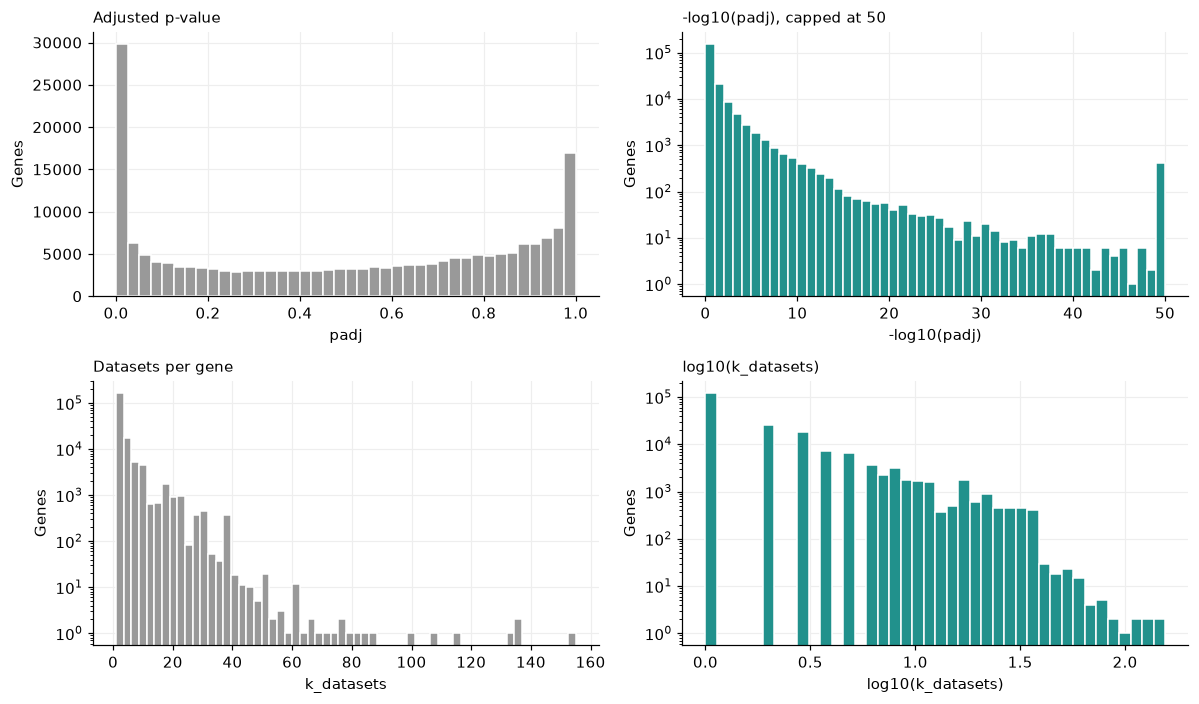

In [61]:
# Skweness before and after transformations
raw_p = genes["padj_meta"]
fig, ax = plt.subplots(2, 2, figsize=(11, 6.5))
ax[0, 0].hist(raw_p, bins=40, color="#999999", edgecolor="white"); ax[0, 0].set_title("Adjusted p-value", fontsize=10, loc="left"); ax[0, 0].set_xlabel("padj")
ax[0, 1].hist(genes["neglog10_padj"], bins=50, color="#21918c", edgecolor="white"); ax[0, 1].set_yscale("log")
ax[0, 1].set_title(f"-log10(padj), capped at {CAP}", fontsize=10, loc="left"); ax[0, 1].set_xlabel("-log10(padj)")
ax[1, 0].hist(genes["k_datasets"], bins=60, color="#999999", edgecolor="white"); ax[1, 0].set_yscale("log")
ax[1, 0].set_title("Datasets per gene", fontsize=10, loc="left"); ax[1, 0].set_xlabel("k_datasets")
ax[1, 1].hist(np.log10(genes["k_datasets"]), bins=40, color="#21918c", edgecolor="white"); ax[1, 1].set_yscale("log")
ax[1, 1].set_title("log10(k_datasets)", fontsize=10, loc="left"); ax[1, 1].set_xlabel("log10(k_datasets)")
for a in ax.flat: a.set_ylabel("Genes")
plt.tight_layout(); plt.show()

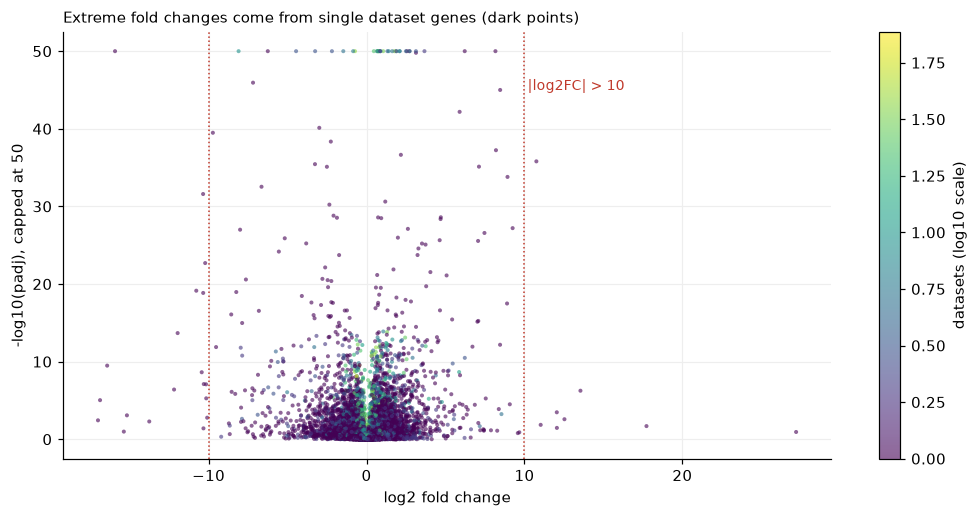

Share of |log2FC| > 10 rows with a single dataset: 94%


In [62]:
# extreme fold changes against significance, colored by dataset support (20,000 random genes)
view = genes.sample(20000, random_state=1)
fig, ax = plt.subplots(figsize=(9.5, 4.8))
sc = ax.scatter(view["log2FoldChange_meta"], view["neglog10_padj"], c=np.log10(view["k_datasets"]), cmap="viridis", s=7, alpha=0.6, linewidths=0)
ax.axvline(-10, color="#c0392b", ls=":", lw=1); ax.axvline(10, color="#c0392b", ls=":", lw=1)
ax.text(10.2, CAP * 0.9, "|log2FC| > 10", color="#c0392b", fontsize=9)
cb = plt.colorbar(sc, ax=ax); cb.set_label("datasets (log10 scale)")
ax.set_xlabel("log2 fold change"); ax.set_ylabel(f"-log10(padj), capped at {CAP}")
ax.set_title("Extreme fold changes come from single dataset genes (dark points)", fontsize=10, loc="left")
plt.tight_layout(); plt.show()
print("Share of |log2FC| > 10 rows with a single dataset:", f"{audit['abs_lfc_gt10_k1'] / audit['abs_lfc_gt10']:.0%}")

The 3% sample tracks the full file closely (the small gap exists because the sample leaves out untested genes, which are all single dataset). Catalog wide percentages in this notebook and the app come from the full counts; the sample is used only for distributions and correlations.

### 4. Q1: How much evidence is there per disease?

I tier each disease by its best supported gene (low = 1 dataset, medium = 2 to 5, high = 6 or more). The left panel counts diseases and right panel shows how skewed the dataset counts are.

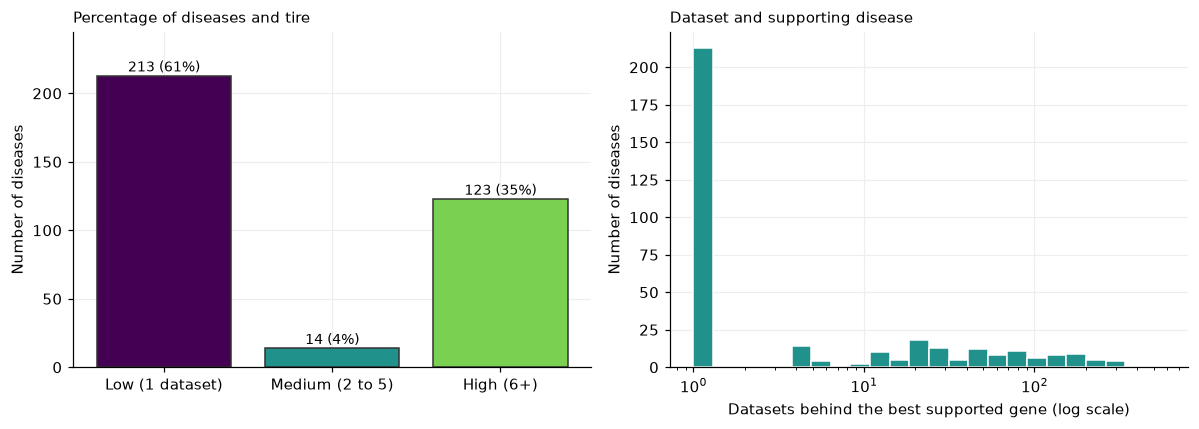

count    350.0
mean      28.1
std       64.1
min        1.0
25%        1.0
50%        1.0
75%       21.0
max      577.0

         n_sig  pct_genes_untested
tier                              
low     2755.0                 0.0
medium  2917.5                10.5
high    2083.0                14.9

Top 5 diseases by dataset support:
                 disease  k_max  n_sig
                Covid-19    577   2540
       Alzheimer-Disease    365    690
Carcinoma-Hepatocellular    322  14311
          Hiv-Infections    303   1429
               Leiomyoma    302   6750


In [63]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
counts = diseases["tier"].value_counts().reindex(TIER_ORDER)
bars = ax[0].bar([TIER_LABEL[t] for t in TIER_ORDER], counts, color=[TIER_COLOR[t] for t in TIER_ORDER], edgecolor="#333")
for b, c in zip(bars, counts):
    ax[0].text(b.get_x() + b.get_width() / 2, c + 3, f"{c} ({c/len(diseases):.0%})", ha="center", fontsize=9)
ax[0].set_ylabel("Number of diseases"); ax[0].set_ylim(0, counts.max() * 1.15)
ax[0].set_title("Percentage of diseases and tire", fontsize=10, loc="left")

ax[1].hist(diseases["k_max"], bins=np.logspace(0, np.log10(diseases["k_max"].max() + 1), 25), color="#21918c", edgecolor="white")
ax[1].set_xscale("log"); ax[1].set_xlabel("Datasets behind the best supported gene (log scale)"); ax[1].set_ylabel("Number of diseases")
ax[1].set_title("Dataset and supporting disease", fontsize=10, loc="left")
plt.tight_layout(); plt.show()

print(diseases["k_max"].describe().round(1).to_string())
print()
print(diseases.groupby("tier")[["n_sig", "pct_genes_untested"]].median().reindex(TIER_ORDER).round(1))
print("\nTop 5 diseases by dataset support:")
print(diseases.nlargest(5, "k_max")[["disease", "k_max", "n_sig"]].to_string(index=False))

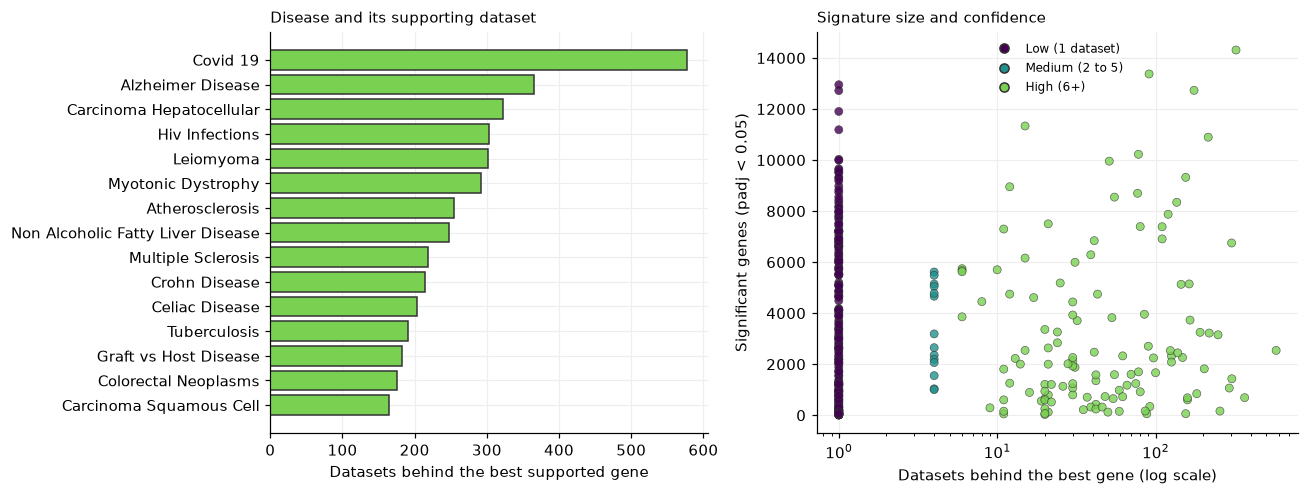

Spearman rho, best gene datasets vs significant genes across 350 diseases: -0.018 (p = 0.74)


In [64]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.6), gridspec_kw={"width_ratios": [1, 1.1]})
t15 = diseases.nlargest(15, "k_max").sort_values("k_max")
ax[0].barh(t15["disease"].str.replace("-", " "), t15["k_max"], color="#7ad151", edgecolor="#333")
ax[0].set_xlabel("Datasets behind the best supported gene"); ax[0].set_title("Disease and its supporting dataset", fontsize=10, loc="left")
ax[1].scatter(diseases["k_max"], diseases["n_sig"], c=[TIER_COLOR[t] for t in diseases["tier"]], edgecolor="#333", linewidth=0.4, s=28, alpha=0.8)
ax[1].set_xscale("log"); ax[1].set_xlabel("Datasets behind the best gene (log scale)"); ax[1].set_ylabel("Significant genes (padj < 0.05)")
ax[1].set_title("Signature size and confidence", fontsize=10, loc="left")
from matplotlib.lines import Line2D
ax[1].legend(handles=[Line2D([0], [0], marker="o", ls="", color=TIER_COLOR[t], markeredgecolor="#333", label=TIER_LABEL[t]) for t in TIER_ORDER], frameon=False, fontsize=8)
plt.tight_layout(); plt.show()
r, p = stats.spearmanr(diseases["k_max"], diseases["n_sig"])
print(f"Spearman rho, best gene datasets vs significant genes across 350 diseases: {r:.3f} (p = {p:.2f})")

**Interpretation (Q1):** 213 of 350 diseases (61%) rest on a single dataset, only 14 (4%) have a best gene with 2 to 5 datasets, and 123 (35%) reach 6 or more. The median disease best gene has just 1 dataset, while Covid 19, Alzheimer Disease and Carcinoma Hepatocellular have 577, 365 and 322. Counting gene results instead of diseases gives the same picture (64% single dataset). Signature size does not tell you the support, the median number of significant genes is similar across tiers (2,755 low, 2,918 medium, 2,083 high).

**Limitation.** Dataset count is a stand in for confidence. A single large clean study can beat several small ones, and OCTAD 2.0's k_datasets reaches the hundreds for some diseases, so it may count comparisons rather than distinct studies. I use it to rank relative support, not to count papers.

### 5. Q2: Do more datasets mean stronger or larger signals?

Using the 3% random gene sample (200,591 genes from all 350 diseases), I compare significance and effect size by tier.

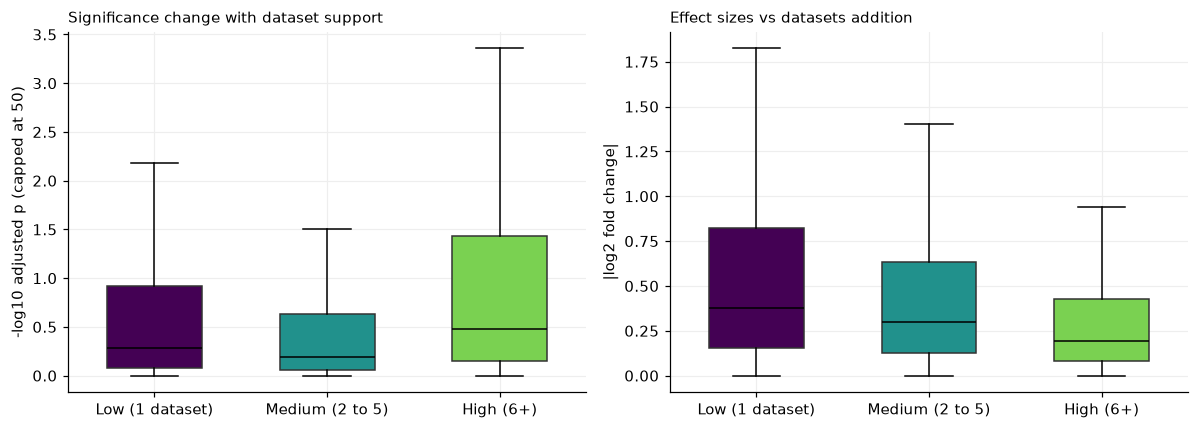

In [65]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
data_sig = [genes.loc[genes["tier"] == t, "neglog10_padj"] for t in TIER_ORDER]
data_lfc = [genes.loc[genes["tier"] == t, "abs_lfc"] for t in TIER_ORDER]
for a, data, ylab, ttl in [(ax[0], data_sig, f"-log10 adjusted p (capped at {CAP})", "Significance change with dataset support"),
                           (ax[1], data_lfc, "|log2 fold change|", "Effect sizes vs datasets addition")]:
    bp = a.boxplot(data, tick_labels=[TIER_LABEL[t] for t in TIER_ORDER], patch_artist=True, showfliers=False, widths=0.55,
                   medianprops=dict(color="black"))
    for patch, t in zip(bp["boxes"], TIER_ORDER):
        patch.set_facecolor(TIER_COLOR[t]); patch.set_edgecolor("#333")
    a.set_ylabel(ylab); a.set_title(ttl, fontsize=10, loc="left")
plt.tight_layout(); plt.show()

In [66]:
summary = genes.groupby("tier", observed=True).agg(
    genes=("gene_symbol", "size"),
    share_significant=("padj_meta", lambda s: (s < 0.05).mean()),
    median_neglog10_padj=("neglog10_padj", "median"),
    median_abs_lfc=("abs_lfc", "median"),
).round(3)
display(summary)

r_sig, p_sig = stats.spearmanr(genes["k_datasets"], genes["neglog10_padj"])
r_lfc, p_lfc = stats.spearmanr(genes["k_datasets"], genes["abs_lfc"])
print(f"Spearman, k_datasets vs significance (all genes):   rho = {r_sig:.3f}, p = {p_sig:.2g}")
print(f"Spearman, k_datasets vs |log2FC| (all genes):       rho = {r_lfc:.3f}, p = {p_lfc:.2g}")

,genes,share_significant,median_neglog10_padj,median_abs_lfc
tier,,,,
low,122825,0.187,0.284,0.378
medium,57803,0.134,0.194,0.297
high,19963,0.271,0.480,0.195


Spearman, k_datasets vs significance (all genes):   rho = 0.014, p = 4.8e-10
Spearman, k_datasets vs |log2FC| (all genes):       rho = -0.156, p = 0


In [67]:
# Does the answer depend on which genes you look at?
r_top, _ = stats.spearmanr(top["k_datasets"], top["neglog10_padj"])
multi_set = set(diseases.loc[diseases["k_max"] >= 2, "disease"])
gm = genes[genes["disease"].isin(multi_set)]
r_multi, _ = stats.spearmanr(gm["k_datasets"], gm["neglog10_padj"])
print(f"\nSame correlation (k vs significance) in other subsets:")
print(f"  only the top 300 genes per disease:                rho = {r_top:.3f}")
print(f"  only diseases with 2+ datasets (random genes):     rho = {r_multi:.3f}")


Same correlation (k vs significance) in other subsets:
  only the top 300 genes per disease:                rho = 0.148
  only diseases with 2+ datasets (random genes):     rho = 0.230


**Interpretation (Q2).** Significance is almost unrelated to dataset support (Spearman rho = 0.01). 18.7% of single dataset genes are significant (padj < 0.05) against 27.1% of genes with 6 or more datasets, and the median significance values are similar (0.28 vs 0.48). Effect sizes, however, shrink as datasets are added, the median |log2FC| falls from 0.38 for single dataset genes to 0.30 (2 to 5 datasets) and 0.20 (6 or more), rho = -0.16.

The correlation depends on which genes you look at. it is 0.15 among each disease's top 300 genes and 0.23 inside diseases that have 2 or more datasets. My earlier homework sample, built from only the top 10 genes of a few diseases, showed a moderate positive relationship (rho around 0.4). That was largely selection restricting to the strongest genes compresses the range and builds in a link between pooled sample size and tiny p-values. The full catalog does not support "more datasets means more significant".

**Alternative explanations.** (1) A meta analysis pools more samples as datasets are added, so p-values shrink by construction. (2) Shrinking effect sizes are consistent with a single small study is more likely to report an exaggerated effect, and pooling pulls it back toward the truth. Either way, a single dataset gene with a large fold change deserves more skepticism.

### 6. Q3: Do more datasets bring more agreement?

I² can only be computed for genes with 2 or more datasets (I set it to missing for k = 1 in preparation). I bin genes by dataset count and look at the spread of I².

In [68]:
multi = genes.dropna(subset=["I2"]).copy()
bins = [1, 2, 5, 10, 50, 1000]
labels = ["2", "3 to 5", "6 to 10", "11 to 50", "51+"]
multi["k_bin"] = pd.cut(multi["k_datasets"], bins=bins, labels=labels)

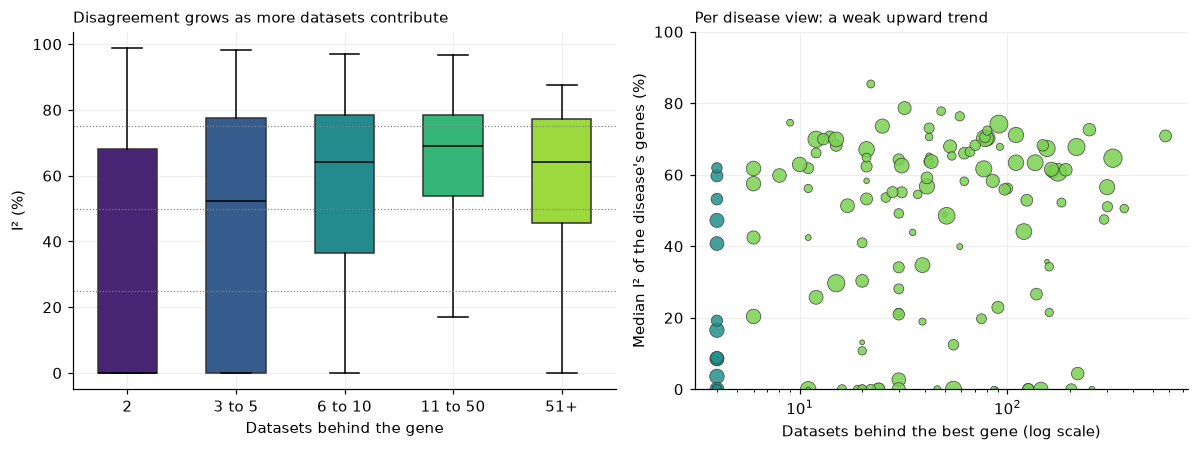

In [69]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4.2), gridspec_kw={"width_ratios": [1.1, 1]})
cols = plt.cm.viridis(np.linspace(0.1, 0.85, len(labels)))
bp = ax[0].boxplot([multi.loc[multi["k_bin"] == l, "I2"] for l in labels], tick_labels=labels, patch_artist=True, showfliers=False,
                   widths=0.55, medianprops=dict(color="black"))
for patch, c in zip(bp["boxes"], cols):
    patch.set_facecolor(c); patch.set_edgecolor("#333")
for y in (25, 50, 75):
    ax[0].axhline(y, color="grey", ls=":", lw=0.8)
ax[0].set_xlabel("Datasets behind the gene"); ax[0].set_ylabel("I² (%)")
ax[0].set_title("Disagreement grows as more datasets contribute", fontsize=10, loc="left")

m = diseases[diseases["k_max"] >= 2].dropna(subset=["median_I2_k2plus"])
ax[1].scatter(m["k_max"], m["median_I2_k2plus"], s=np.sqrt(m["n_sig"]) * 1.2, c=[TIER_COLOR[t] for t in m["tier"]], edgecolor="#333", alpha=0.85, linewidth=0.5)
ax[1].set_xscale("log"); ax[1].set_xlabel("Datasets behind the best gene (log scale)"); ax[1].set_ylabel("Median I² of the disease's genes (%)")
ax[1].set_title("Per disease view: a weak upward trend", fontsize=10, loc="left"); ax[1].set_ylim(0, 100)
plt.tight_layout(); plt.show()

In [70]:
print(multi.groupby("k_bin", observed=True)["I2"].agg(genes="size", median="median", share_I2_zero=lambda s: (s == 0).mean(), share_over_50=lambda s: (s >= 50).mean()).round(3))
r, p = stats.pearsonr(multi["k_datasets"], multi["I2"]); rho, p2 = stats.spearmanr(multi["k_datasets"], multi["I2"])
print(f"\nGene level (2+ datasets, n = {len(multi):,}):  Pearson r = {r:.3f}, Spearman rho = {rho:.3f}  (p < 0.001 for both)")
rd, pd_ = stats.spearmanr(m["k_max"], m["median_I2_k2plus"])
print(f"Disease level ({len(m)} diseases):               Spearman rho = {rd:.3f}, p = {pd_:.3f}")

          genes  median  share_I2_zero  share_over_50
k_bin                                                
2         25950   0.000          0.523          0.338
3 to 5    31853  52.189          0.289          0.515
6 to 10   12400  64.149          0.125          0.656
11 to 50   7512  69.128          0.035          0.795
51+          51  64.161          0.059          0.686

Gene level (2+ datasets, n = 77,766):  Pearson r = 0.240, Spearman rho = 0.289  (p < 0.001 for both)
Disease level (137 diseases):               Spearman rho = 0.189, p = 0.027


**Interpretation (Q3).** More datasets go with more measured disagreement. For genes with exactly 2 datasets the median I² is 0 (52% of them have I² of exactly 0), for 3 to 5 datasets the median is 52%, for 6 to 10 it is 64% and for 11 to 50 it is 69%. Gene level Spearman rho = 0.29. At the disease level the trend is weaker (rho = 0.19, p = 0.027), even well studied diseases range from low to considerable disagreement. A low I² from two datasets is weak reassurance, because two studies can barely show disagreement, many datasets with a high I² means well replicated in count but not in agreement. This is why the app shows I² next to the dataset count instead of folding both into one score.

**Limitation.** I² itself is unstable when there are few studies.

### 6b. All relationships at a glance

Correlation matrix for the numeric variables. It summarizes Q2 and Q3 in one picture. I² only exists for genes with 2 or more datasets, so it uses those rows.

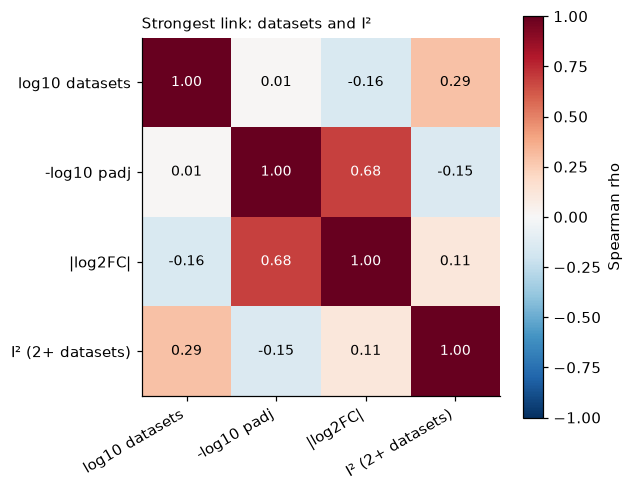

In [71]:
num = genes.assign(log10_k=np.log10(genes["k_datasets"]))[["log10_k", "neglog10_padj", "abs_lfc", "I2"]].rename(
    columns={"log10_k": "log10 datasets", "neglog10_padj": "-log10 padj", "abs_lfc": "|log2FC|", "I2": "I² (2+ datasets)"})
corr = num.corr(method="spearman")      # pairwise complete, so I² uses only rows where it exists
fig, ax = plt.subplots(figsize=(5.8, 4.8))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr))); ax.set_xticklabels(corr.columns, rotation=30, ha="right"); ax.set_yticks(range(len(corr))); ax.set_yticklabels(corr.columns)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", color="white" if abs(corr.iloc[i, j]) > 0.5 else "black", fontsize=9)
ax.grid(False); plt.colorbar(im, ax=ax, label="Spearman rho"); ax.set_title("Strongest link: datasets and I²", fontsize=10, loc="left")
plt.tight_layout(); plt.show()

### 7. Course concepts check: what was applied and what was deliberately not

| Concept | Decision | Reason |
|---|---|---|
| Data type and quality audit | Applied | Done on the full file, not only a sample |
| Missingness | Assessed, not imputed | Missing p-values occur only in single dataset genes, so the gap is informative |
| Transformation | Applied | -log10 for p-values, log axes for counts, tiers for communication/visualization |
| Representation imbalance | Applied | 61% of diseases sit in one tier, so any single average would mislead |
| Integration | Applied | 350 per disease files stacked into one table (same columns) |
| Encoding, scaling | N/A | No model applied |
| Modeling / regression | Not applied | The idea was to be descriptive not predictive |

### 8. What this means for the demo app, and limitations

- The app opens with the main message (61% of diseases rest on one dataset) and gives every disease a confidence card (tier, best gene datasets, significant genes, I² label, % untested)
- The volcano view colors genes by dataset count and shows the display cap and the padj = 0.05 line
- The compare tab shows catalog wide imbalance and the dataset count vs I² relationship, with a filterable full table

**Limitations.** The whole project and app is only descriptive. Datasets count is a proxy for confidence. The app plots only the strongest 300 genes per disease, so pathway level patterns and weaker genes are not shown. Tier cut points (1, 2 to 5, 6 or more) are my choices. Differences between tiers are partly confounded with disease type (well studied disease such as cancers vs rare conditions), which this analysis does not separate.

## 9. AI use disclosure

- **Tool and version:** Claude Sonnet 5.5
- **Purposes:** Drafting python scripts for plotting code, the Streamlit app
- **Representative prompts:** Asked few things during the ideation process such as: "What are the pros and cons of using the whole OCTAD dataset?"
- **How outputs were checked:** All counts were recomputed from the full 7.3 million row file and compared with the app and this notebook, the earlier hand picked sample for HW5 was replaced after I noticed it gave a misleading tier split, chart scales, transformations and labels were inspected.
- **My own contribution:** the project question, framing, decision, the choice to treat dataset support as the confidence signal, the decisions in section 3, and interpretations.